# France: a first look at the data

Before we stress-test anything, we need to know where France starts from. This notebook is that starting picture: how democratic France is rated, what happened at its last election, how many people vote, and how much people trust their institutions. Wherever we can, we put France next to the rest of the EU, because a number on its own says little.

We use these sources:

- **V-Dem** and **Freedom House** for how democratic France is. Both are expert ratings, not polls.
- **PPEG** for the 2024 legislative results, and **International IDEA** for turnout.
- **Eurobarometer** for trust, with the French **CEVIPOF** survey as a second opinion.
- Our own **data checks** (in `outputs/data_audit/`) for what to be careful about.

Everything here describes what has already happened. Nothing in it predicts what will happen next. If you want to go further, `02_shock_numbers.ipynb` looks at past crises and `03_radical_voting.ipynb` at radical voting.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown

# Works whether you open the notebook from the project folder or from notebooks/.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROCESSED = ROOT / 'data/processed'
CHECKS = ROOT / 'outputs/data_audit'
pd.set_option('display.float_format', '{:.1f}'.format)

# The 27 EU countries. Some sources have no EU figure of their own, so we compare France with these.
EU27 = ['AUT', 'BEL', 'BGR', 'HRV', 'CYP', 'CZE', 'DNK', 'EST', 'FIN', 'FRA', 'DEU', 'GRC', 'HUN', 'IRL',
        'ITA', 'LVA', 'LTU', 'LUX', 'MLT', 'NLD', 'POL', 'PRT', 'ROU', 'SVK', 'SVN', 'ESP', 'SWE']

vdem = pd.read_csv(PROCESSED / 'vdem_country_year_core_v16.csv')
freedom = pd.read_csv(PROCESSED / 'freedom_house_country_year_owid.csv')
election = pd.read_csv(PROCESSED / 'ppeg_france_latest_parliamentary.csv')
turnout = pd.read_csv(PROCESSED / 'idea_france_elections.csv', parse_dates=['election_date'])
trust = pd.read_csv(PROCESSED / 'eurobarometer_trust_trend.csv', parse_dates=['fieldwork_start'])
cevipof = pd.read_csv(PROCESSED / 'cevipof_trust_2026_published.csv')
sources = pd.read_csv(CHECKS / 'source_profiles.csv')
problems = pd.read_csv(CHECKS / 'quality_issues.csv')
print(f"Ready: {len(sources)} sources described and {len(problems)} data problems noted.")

Ready: 23 sources described and 16 data problems noted.


## 1. What data do we have?

A quick tour of our sources: how big each one is, how much of it is about France, and which years it covers. If a source has very few French rows, that's a warning sign before we lean on it. The [data guide](../data_sets_legend.txt) explains each source in plain words.

In [2]:
overview = sources[['source', 'grain', 'rows', 'france_rows', 'first_year', 'last_year', 'note']].copy()
for column in ['rows', 'france_rows', 'first_year', 'last_year']:
    overview[column] = overview[column].astype('Int64')  # whole numbers, blanks stay blank
overview.rename(columns={'grain': 'one row per', 'france_rows': 'rows about France',
                         'first_year': 'from', 'last_year': 'to'}).set_index('source')

,one row per,rows,rows about France,from,to,note
source,,,,,,
V-Dem v16,country-year,4636,26,2000,2025,NaN
OWID democracy,chart/explorer export,9814,47,<NA>,<NA>,2 CSV files; 0 read errors
ParlGov view_party,party,1707,80,<NA>,<NA>,2024 release
ParlGov view_election,election,9016,392,1900,2023,2024 release
ParlGov view_cabinet,cabinet,12659,1113,1900,2023,2024 release
PPEG parl,parl,12577,269,1942,2025,NaN
PPEG pres,pres,2829,115,1945,2025,NaN
PPEG gov,gov,5864,327,1942,2025,NaN
PPEG comb,comb,25107,970,1942,2025,Combined archive overlaps the component archives


## 2. How democratic is France, compared with the rest of the EU?

Two well-known ratings, side by side. The blue line is France. The dashed line is the **typical EU country**, the one in the middle when all 27 are ranked (the median).

V-Dem also says how sure it is: the shaded band shows the range its experts consider plausible. If France's line moves but stays inside that band, we can't really call it a change.

The two ratings use different scales (0–1 and 0–100), so compare France with the EU within each chart, not across the two.

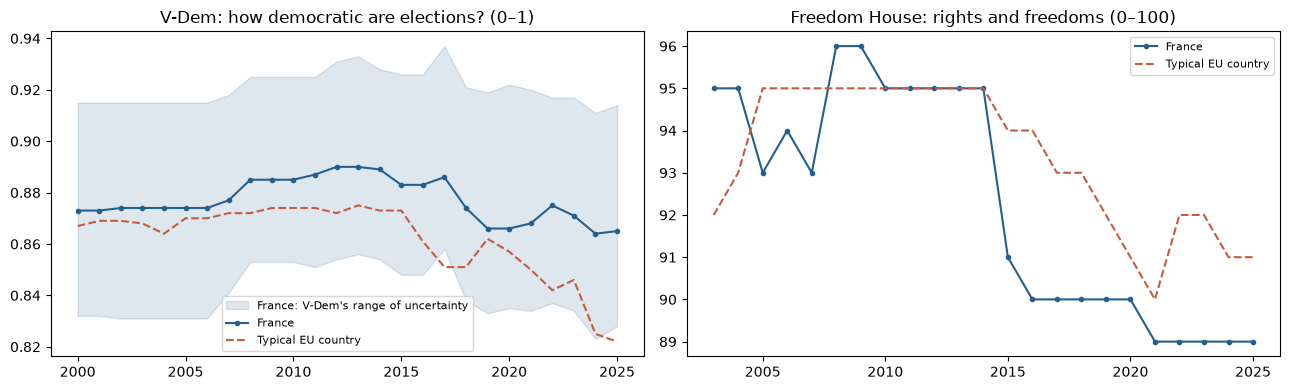

,France,typical EU country,France's rank out of 27,year
V-Dem: electoral democracy,0.865,0.822,7,2025
V-Dem: liberal democracy,0.800,0.741,6,2025
Freedom House score,89.000,91.000,17,2025


In [3]:
vdem_eu = vdem[vdem.country_text_id.isin(EU27)]
freedom_eu = freedom[freedom.iso3.isin(EU27)]
vdem_france = vdem_eu[vdem_eu.country_text_id == 'FRA'].sort_values('year')
freedom_france = freedom_eu[freedom_eu.iso3 == 'FRA'].sort_values('year')

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4))
left.fill_between(vdem_france.year, vdem_france.v2x_polyarchy_codelow, vdem_france.v2x_polyarchy_codehigh,
                  color='#245f91', alpha=.15, label="France: V-Dem's range of uncertainty")
left.plot(vdem_france.year, vdem_france.v2x_polyarchy, color='#245f91', marker='o', ms=3, label='France')
left.plot(*vdem_eu.groupby('year').v2x_polyarchy.median().reset_index().values.T, color='#c45d3f', ls='--', label='Typical EU country')
left.set_title('V-Dem: how democratic are elections? (0–1)')
left.legend(fontsize=8)
right.plot(freedom_france.year, freedom_france.freedom_score, color='#245f91', marker='o', ms=3, label='France')
right.plot(*freedom_eu.groupby('year').freedom_score.median().reset_index().values.T, color='#c45d3f', ls='--', label='Typical EU country')
right.set_title('Freedom House: rights and freedoms (0–100)')
right.legend(fontsize=8)
plt.tight_layout()
plt.show()

# The latest year of each rating, and where France ranks among the 27 (1 = best).
vdem_year, freedom_year = int(vdem_france.year.max()), int(freedom_france.year.max())
vdem_latest = vdem_eu[vdem_eu.year == vdem_year]
freedom_latest = freedom_eu[freedom_eu.year == freedom_year]
scores = pd.DataFrame({
    'France': [vdem_france.v2x_polyarchy.iloc[-1], vdem_france.v2x_libdem.iloc[-1], freedom_france.freedom_score.iloc[-1]],
    'typical EU country': [vdem_latest.v2x_polyarchy.median(), vdem_latest.v2x_libdem.median(), freedom_latest.freedom_score.median()],
    "France's rank out of 27": [vdem_latest.v2x_polyarchy.rank(ascending=False)[vdem_france.index[-1]],
                                vdem_latest.v2x_libdem.rank(ascending=False)[vdem_france.index[-1]],
                                freedom_latest.freedom_score.rank(ascending=False, method='min')[freedom_france.index[-1]]],
    'year': [vdem_year, vdem_year, freedom_year]},
    index=['V-Dem: electoral democracy', 'V-Dem: liberal democracy', 'Freedom House score'])
scores.style.format({'France': '{:.3f}', 'typical EU country': '{:.3f}', "France's rank out of 27": '{:.0f}', 'year': '{:.0f}'})

## 3. What happened at the 2024 legislative election?

For each of the eight biggest lists: the share of votes it won in the first round (blue), and the share of seats it ended up with after the second round (red). When the two bars differ a lot, the voting system rewarded or punished that list.

One thing to know: the **New Popular Front** and **Ensemble** ran as alliances of several parties, and the data only gives their combined result. We can't tell how many of those votes went to each member party.

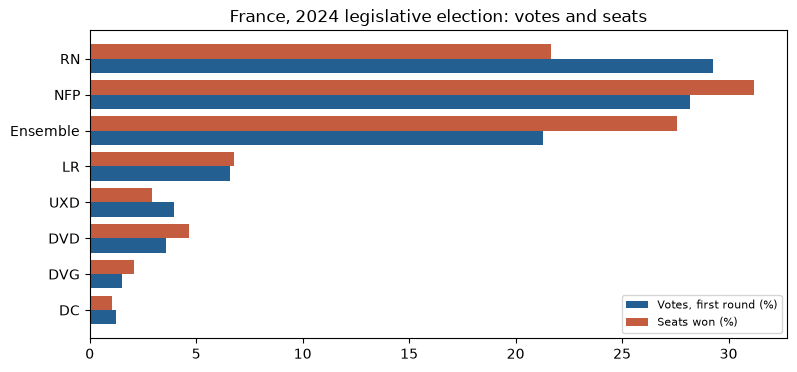

,full name,what it is,votes %,seats %
list,,,,
RN,National Rally,party in an alliance,29.3,21.7
NFP,New Popular Front,alliance,28.2,31.2
Ensemble,Together,alliance,21.3,27.6
LR,The Republicans,party,6.6,6.8
UXD,Union of the Far-Right,party in an alliance,4.0,2.9
DVD,Miscellaneous Right,party,3.6,4.7
DVG,Miscellaneous left,party,1.5,2.1
DC,Miscellaneous Centre,party,1.2,1.0


In [4]:
lists = (election.assign(name=election.pinitials.fillna(election.pname_en))
         .sort_values('vote_pct', ascending=False).head(8))
fig, ax = plt.subplots(figsize=(9, 4))
rows = range(len(lists))
ax.barh([i + 0.2 for i in rows], lists.vote_pct, height=0.4, color='#245f91', label='Votes, first round (%)')
ax.barh([i - 0.2 for i in rows], lists.seat_pct, height=0.4, color='#c45d3f', label='Seats won (%)')
ax.set_yticks(list(rows), lists.name)
ax.invert_yaxis()  # biggest list at the top
ax.set_title('France, 2024 legislative election: votes and seats')
ax.legend(fontsize=8)
plt.show()

kind = lists.alliance.fillna('party').replace({'Electoral alliance member': 'party in an alliance', 'Electoral alliance': 'alliance'})
lists.assign(kind=kind)[['name', 'pname_en', 'kind', 'vote_pct', 'seat_pct']].rename(
    columns={'name': 'list', 'pname_en': 'full name', 'kind': 'what it is', 'vote_pct': 'votes %', 'seat_pct': 'seats %'}).set_index('list')

## 4. How many French people vote?

Turnout at legislative (blue) and presidential (red) elections, as a share of registered voters. French elections have two rounds a week or two apart, so we draw them as separate lines: **solid for the first round, dashed for the second**. That way each line only links like with like. Presidential elections usually draw far more voters than legislative ones; watch what happened in 2024.

A few older elections only have a year, not an exact date, in the source. We leave those out of the chart rather than guess the day.

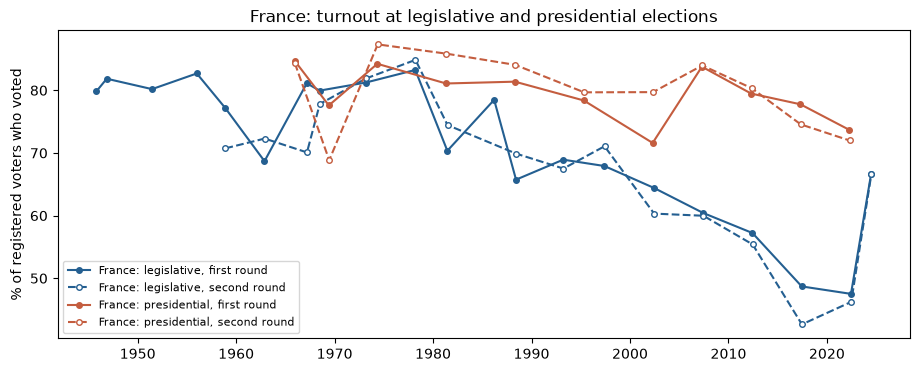

,election,turnout %
date,,
10 Apr 2022,presidential,73.7
24 Apr 2022,presidential,72.0
12 Jun 2022,legislative,47.5
19 Jun 2022,legislative,46.2
30 Jun 2024,legislative,66.7
07 Jul 2024,legislative,66.6


In [5]:
dated = turnout[turnout.election_date_precision.eq('day_reported') & turnout['Election Type'].isin(['Parliamentary', 'Presidential'])]
# Number the rounds: within the same year and type of election, the earlier date is round 1.
dated = dated.sort_values('election_date')
dated['round'] = dated.groupby(['Election Type', dated.election_date.dt.year]).cumcount() + 1

fig, ax = plt.subplots(figsize=(11, 4))
for kind, color, label in [('Parliamentary', '#245f91', 'legislative'), ('Presidential', '#c45d3f', 'presidential')]:
    for round_number, style, fill in [(1, '-', color), (2, '--', 'white')]:
        series = dated[(dated['Election Type'] == kind) & (dated['round'] == round_number)]
        ax.plot(series.election_date, series.registered_turnout_pct, ls=style, marker='o', ms=4, color=color,
                markerfacecolor=fill, label=f"France: {label}, {'first' if round_number == 1 else 'second'} round")
ax.set_ylabel('% of registered voters who voted')
ax.set_title('France: turnout at legislative and presidential elections')
ax.legend(fontsize=8)
plt.show()

recent = dated.sort_values('election_date').tail(6)
recent.assign(date=recent.election_date.dt.strftime('%d %b %Y'),
              election=recent['Election Type'].replace({'Parliamentary': 'legislative', 'Presidential': 'presidential'}))[
    ['date', 'election', 'registered_turnout_pct']].rename(columns={'registered_turnout_pct': 'turnout %'}).set_index('date')

## 5. Do people trust parliament, government and parties?

Twice a year, Eurobarometer asks people in every EU country whether they "tend to trust" each institution. The blue line is France, the red line is the EU as a whole. Each dot is one survey.

Each survey interviews about a thousand people per country, so a jump of a few points between two surveys can be chance. Look at the longer trend and at the gap between the two lines.

The French CEVIPOF survey asks a similar but not identical question. We show its latest numbers next to the table as a second opinion, but we don't mix them into the charts.

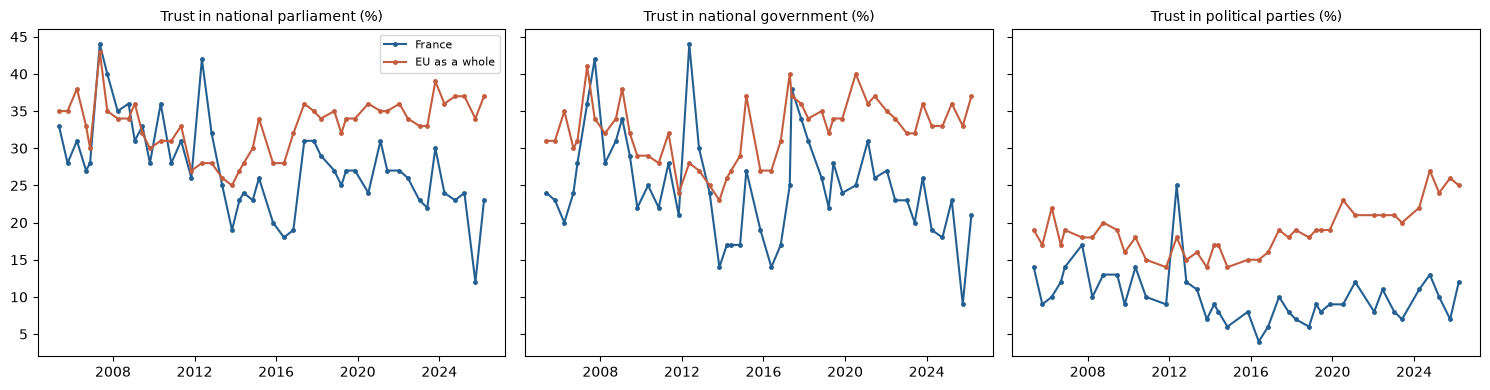

Latest Eurobarometer survey: wave 105.2, interviews from 12 Mar 2026


,France,EU as a whole,difference (France − EU),"CEVIPOF, France, Feb 2026 (similar question)"
institution,,,,
National government,21.0,37.0,-16.0,17
National parliament,23.0,37.0,-14.0,20
Political parties,12.0,25.0,-13.0,15


In [6]:
INSTITUTIONS = ['National parliament', 'National government', 'Political parties']
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, institution in zip(axes, INSTITUTIONS):
    for code, label, color in [('FR', 'France', '#245f91'), ('EU', 'EU as a whole', '#c45d3f')]:
        series = trust[(trust.country_code == code) & (trust.institution == institution)].sort_values('fieldwork_start')
        ax.plot(series.fieldwork_start, series.trust_pct, marker='o', ms=2.5, color=color, label=label)
    ax.set_title(f'Trust in {institution.lower()} (%)', fontsize=10)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# The most recent survey: France next to the EU, plus CEVIPOF's French figures.
latest_wave = trust.loc[trust.country_code == 'FR', 'wave'].max()
survey_date = trust.loc[trust.wave == latest_wave, 'fieldwork_start'].min()
trust_now = trust[trust.wave == latest_wave].pivot_table(index='institution', columns='country_code', values='trust_pct')[['FR', 'EU']]
trust_now.columns = ['France', 'EU as a whole']
trust_now['difference (France − EU)'] = trust_now['France'] - trust_now['EU as a whole']
cevipof_france = cevipof[cevipof.country == 'France'].set_index('institution').trust_pct
trust_now['CEVIPOF, France, Feb 2026 (similar question)'] = pd.Series({
    'National parliament': cevipof_france.get('National Assembly'),
    'National government': cevipof_france.get('Government'),
    'Political parties': cevipof_france.get('Political parties')})
print(f"Latest Eurobarometer survey: wave {latest_wave}, interviews from {survey_date:%d %b %Y}")
trust_now

## 6. What should we be careful about?

While checking the downloads we noted every problem we found: missing pieces, duplicates, things that don't line up between sources. Here is the full list, with what we suggest doing about each one. Most are small; the ones about party **alliances** matter most, because they make it hard to link votes to parties.

In [7]:
pd.set_option('display.max_colwidth', 120)
problems[['source', 'severity', 'finding', 'action']].rename(
    columns={'severity': 'type of problem', 'finding': 'what we found', 'action': 'what to do'}).set_index('source')

,type of problem,what we found,what to do
source,,,
OWID Freedom House,cleaning,Summary rows have no country code,"Leave them in the raw files, and use only coded countries in the country-year table."
ParlGov view_cabinet,review,Some rows share the proposed identifier,Open these rows and check which field distinguishes them before removing anything.
PPEG pres,review,Some rows share the proposed identifier,Open these rows and check which field distinguishes them before removing anything.
PPEG pres,review,Some rows lack an identifier,Keep these rows and find out why the identifier is missing.
PPEG comb,review,Some rows share the proposed identifier,Open these rows and check which field distinguishes them before removing anything.
PPEG + CHES,join,Election alliances and CHES parties are different units,Check alliance membership before linking vote shares to CHES party positions.
IDEA turnout,date,Many election dates look like year placeholders,Use the year for now. Check another election source before assigning an exact day.
IDEA turnout,error,Three reported turnout rates exceed 100%,Keep the reported rates for reference; leave the validated rates blank.
IDEA turnout,review,Some rows lack an identifier,Keep these rows and find out why the identifier is missing.


## 7. What did we learn?

A short write-up of the main points. It's generated from the tables above, so if the data are updated, these sentences update too. Before quoting a number, check the table it comes from.

In [8]:
# A few figures the sentences below need.
by_list = election.set_index(election.pinitials.fillna(election.pname_en))
biggest = by_list.vote_pct.idxmax()
seats_minus_votes = by_list.vote_pct - by_list.seat_pct  # positive = fewer seats than votes
legislative = dated[dated['Election Type'] == 'Parliamentary'].sort_values('election_date')
first_rounds = legislative.groupby(legislative.election_date.dt.year).head(1)
first_rounds = first_rounds.set_index(first_rounds.election_date.dt.year)
this_time, last_time = first_rounds.index[-1], first_rounds.index[-2]
widest_gap = trust_now['difference (France − EU)'].idxmin()

vdem_now = scores.loc['V-Dem: electoral democracy']
freedom_now = scores.loc['Freedom House score']
steady = vdem_france.v2x_polyarchy.max() - vdem_france.v2x_polyarchy.min() < 0.05
vdem_above = vdem_now['France'] > vdem_now['typical EU country']
rank = int(vdem_now["France's rank out of 27"])
ordinal = f"{rank}{'th' if 10 <= rank % 100 <= 20 else {1: 'st', 2: 'nd', 3: 'rd'}.get(rank % 10, 'th')}"
freedom_above = freedom_now['France'] > freedom_now['typical EU country']

out = ['### Where France stands',
       f"- **France is rated a solid democracy{', and that has hardly changed' if steady else ''}.** On V-Dem it scores "
       f"{vdem_now['France']:.3f} out of 1 in {vdem_year} (it has stayed between {vdem_france.v2x_polyarchy.min():.3f} and "
       f"{vdem_france.v2x_polyarchy.max():.3f} since {vdem_france.year.min()}), above the typical EU country's "
       f"{vdem_now['typical EU country']:.3f}. That puts it {ordinal} of the 27. "
       f"Freedom House gives it {freedom_now['France']:.0f} out of 100, against {freedom_now['typical EU country']:.0f} for the typical EU country.",
       (f"- **But the two ratings don't agree.** V-Dem puts France {'above' if vdem_above else 'below'} the typical EU country, "
        f"Freedom House {'above' if freedom_above else 'below'} it. Freedom House has also lowered France over time, from "
        f"{freedom_france.freedom_score.max():.0f} at its best to {freedom_france.freedom_score.iloc[-1]:.0f} in {freedom_year}. "
        "It's worth reporting both rather than picking one."
        if vdem_above != freedom_above
        else "- **The two ratings agree** on where France stands compared with the typical EU country."),
       f"- **French people trust their institutions much less than other Europeans do.** In the latest survey ({survey_date:%B %Y}): "
       + '; '.join(f"{institution.lower()} {row['France']:.0f}% in France against {row['EU as a whole']:.0f}% across the EU"
                   for institution, row in trust_now.iterrows())
       + f". The gap is widest for the {widest_gap.lower()}: {abs(trust_now.loc[widest_gap, 'difference (France − EU)']):.0f} points.",
       f"- **The 2024 election left three big blocs.** {by_list.loc[biggest, 'pname_en']} came first with {by_list.loc[biggest, 'vote_pct']:.1f}% "
       f"of first-round votes, but ended with only {by_list.loc[biggest, 'seat_pct']:.1f}% of the seats. "
       + (f"No other list lost as much between its votes and its seats: {seats_minus_votes.max():.1f} points."
        if seats_minus_votes.idxmax() == biggest else
        f"The list that lost most between votes and seats was {by_list.loc[seats_minus_votes.idxmax(), 'pname_en']}: {seats_minus_votes.max():.1f} points."),
       f"- **Far more people voted.** First-round turnout at the legislative election was {first_rounds.loc[this_time, 'registered_turnout_pct']:.1f}% "
       f"in {this_time}, up from {first_rounds.loc[last_time, 'registered_turnout_pct']:.1f}% in {last_time}.",
       '', '### About the data',
       f"- We describe {len(sources)} sources and have noted {len(problems)} problems. Of these, "
       f"{problems.severity.isin(['review', 'join']).sum()} need someone to look at them by hand, mostly duplicate "
       "IDs and party alliances.",
       '- Alliances are the biggest obstacle to linking votes with party positions. Notebook 03 shows how we deal with them for radical voting.',
       '', '### Before you quote these numbers',
       "- V-Dem and Freedom House are expert judgements on different scales. A V-Dem change smaller than its range of uncertainty isn't a real change.",
       "- Eurobarometer and CEVIPOF ask different questions, so don't put their percentages on the same line.",
       '- Vote shares are from the first round; seats are the final result after both rounds.']
Markdown('\n'.join(out))

### Where France stands
- **France is rated a solid democracy, and that has hardly changed.** On V-Dem it scores 0.865 out of 1 in 2025 (it has stayed between 0.864 and 0.890 since 2000), above the typical EU country's 0.822. That puts it 7th of the 27. Freedom House gives it 89 out of 100, against 91 for the typical EU country.
- **But the two ratings don't agree.** V-Dem puts France above the typical EU country, Freedom House below it. Freedom House has also lowered France over time, from 96 at its best to 89 in 2025. It's worth reporting both rather than picking one.
- **French people trust their institutions much less than other Europeans do.** In the latest survey (March 2026): national government 21% in France against 37% across the EU; national parliament 23% in France against 37% across the EU; political parties 12% in France against 25% across the EU. The gap is widest for the national government: 16 points.
- **The 2024 election left three big blocs.** National Rally came first with 29.3% of first-round votes, but ended with only 21.7% of the seats. No other list lost as much between its votes and its seats: 7.6 points.
- **Far more people voted.** First-round turnout at the legislative election was 66.7% in 2024, up from 47.5% in 2022.

### About the data
- We describe 23 sources and have noted 16 problems. Of these, 8 need someone to look at them by hand, mostly duplicate IDs and party alliances.
- Alliances are the biggest obstacle to linking votes with party positions. Notebook 03 shows how we deal with them for radical voting.

### Before you quote these numbers
- V-Dem and Freedom House are expert judgements on different scales. A V-Dem change smaller than its range of uncertainty isn't a real change.
- Eurobarometer and CEVIPOF ask different questions, so don't put their percentages on the same line.
- Vote shares are from the first round; seats are the final result after both rounds.